# Lab 7 · Example B — Reuters Topic Classification with a Bidirectional LSTM
### Deep Learning Laboratory (23DS5PCDLG) · Student Fill-in Notebook

**Why a second example?** Same ingredients (Embedding → Bidirectional LSTM → Dense), but now the
task has **46 topic classes**, not 2. This shows how the **output layer and loss change** when you
move from *binary* to *multi-class* classification. Spot the differences from Example A!

| | Example A (IMDB) | Example B (Reuters) |
|---|---|---|
| classes | 2 (pos/neg) | **46 topics** |
| output layer | `Dense(1, 'sigmoid')` | **`Dense(46, 'softmax')`** |
| loss | `binary_crossentropy` | **`sparse_categorical_crossentropy`** |

---
Replace every `None  # TODO (Qn)`. Run top to bottom. *(Downloads the Reuters dataset once.)*


## Step 0 — Imports *(given)*

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dense, Dropout, Input
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.datasets import reuters
import matplotlib.pyplot as plt
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## Task 1 — Load and pad the data

Reuters newswires are also pre-encoded as integer indices, each labelled with one of 46 topics.
Keep the top `num_words` words, pad to `maxlen`, and use the built-in test split.

*Hints:* keep 10000 words; pad to 200; count classes with `max(labels)+1`.


In [2]:
num_words = 10000     # TODO (Q1a): 10000
maxlen    = 200    # TODO (Q1a): 200

(X_train, y_train), (X_test, y_test) = reuters.load_data(num_words=num_words, test_split=0.2)

# Q1b) pad both sets
X_train = pad_sequences(X_train, maxlen=maxlen)   # TODO (Q1b): maxlen
X_test  = pad_sequences(X_test,  maxlen=maxlen)   # TODO (Q1b): maxlen

# Q1c) how many topic classes? (labels are integers 0..45)
num_classes = int(max(y_train)) +1  # TODO (Q1c): int(max(y_train)) + 1
print("X_train:", X_train.shape, " classes:", num_classes)

2110848/2110848 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
X_train: (8982, 200)  classes: 46


#### Quick check *(given)*

In [3]:
assert X_train.shape[1] == 200, "pad reviews to length 200"
assert num_classes == 46, "Reuters has 46 topic classes"
print("Task 1 looks correct ✔")

Task 1 looks correct ✔


## Task 2 — Build the model (multi-class head)

Same backbone as Example A, but the **output** changes for 46 classes.

*Hints:* `Embedding(num_words, 128)`; `Bidirectional(LSTM(64, return_sequences=False))`;
output is `Dense(num_classes, activation='softmax')` — one neuron per topic.


In [4]:
model = Sequential()
model.add(Input(shape=(maxlen,)))

# Q2a) Embedding
model.add(Embedding(input_dim=num_words, output_dim=128))   # TODO (Q2a): num_words, 128

# Q2b) Bidirectional LSTM -> one summary vector
model.add(Bidirectional(LSTM(64, return_sequences=False)))   # TODO (Q2b): 64, False

model.add(Dropout(0.5))

# Q2c) Output: one neuron PER CLASS with softmax
model.add(Dense(num_classes, activation='softmax'))   # TODO (Q2c): num_classes, 'softmax'

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 46)             │         5,934 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,384,750 (5.28 MB)

 Trainable params: 1,384,750 (5.28 MB)

 Non-trainable params: 0 (0.00 B)

**Reflection Q2d.** Compare this `model.summary()` with Example A. Which layer changed size,
and why? (Hint: look at the final Dense layer's parameter count.)

> **Your answer (Q2d):** the Dense layer grew from (128+1)×1 to (128+1)×46 because we went from a binary classification task (1 output unit) to a 46-class multi-class classification task (46 output units). Each of the 46 units needs its own set of 128 weights connected to the BiLSTM outputs, plus 1 bias term.

## Task 3 — Compile and train (multi-class loss)

Labels here are **integers** (0–45), not one-hot — so use **`sparse_categorical_crossentropy`**
(it one-hots internally). Optimiser `adam`, track accuracy. Train ~10 epochs, batch 64, with a
20% validation split.


In [5]:
# Q3a) compile for integer multi-class labels
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',              # TODO (Q3a): 'sparse_categorical_crossentropy'
              metrics=['accuracy'])

# Q3b) train with a validation split
history = model.fit(X_train, y_train,
                    validation_split=0.2,  # TODO (Q3b): 0.2
                    epochs=10,             # TODO (Q3b): 10
                    batch_size=64)         # TODO (Q3b): 64

Epoch 1/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 67s 564ms/step - accuracy: 0.4103 - loss: 2.4213 - val_accuracy: 0.5142 - val_loss: 2.0217
Epoch 2/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 62s 549ms/step - accuracy: 0.5193 - loss: 1.9620 - val_accuracy: 0.5298 - val_loss: 1.7549
Epoch 3/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 83s 559ms/step - accuracy: 0.5694 - loss: 1.6952 - val_accuracy: 0.5999 - val_loss: 1.6366
Epoch 4/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 61s 537ms/step - accuracy: 0.6289 - loss: 1.5042 - val_accuracy: 0.6082 - val_loss: 1.5550
Epoch 5/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 60s 536ms/step - accuracy: 0.6539 - loss: 1.3733 - val_accuracy: 0.6099 - val_loss: 1.6231
Epoch 6/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 67s 596ms/step - accuracy: 0.6907 - loss: 1.2233 - val_accuracy: 0.6628 - val_loss: 1.4031
Epoch 7/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 61s 540ms/step - accuracy: 0.7375 - loss: 1.0472 - val_accuracy: 0.6689 - val_loss: 1.3839
Epoch 8/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 68s 602ms/step - accuracy: 0.7585 - loss: 0

## Task 4 — Evaluate and plot *(fill the blanks)*

71/71 ━━━━━━━━━━━━━━━━━━━━ 4s 57ms/step - accuracy: 0.6456 - loss: 1.5518
Test accuracy: 64.56%


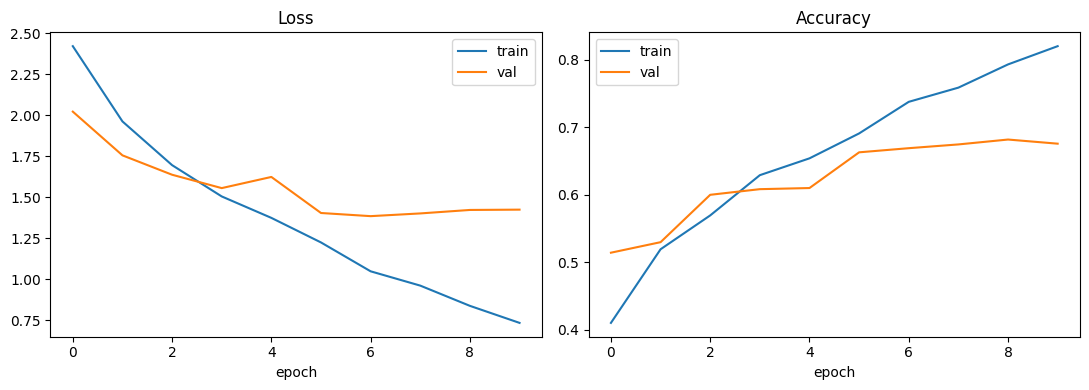

In [6]:
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test accuracy: {accuracy*100:.2f}%")   # expect ~ 65-72%

plt.figure(figsize=(11,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')      # TODO (Q4a): 'val_loss'
plt.title('Loss'); plt.xlabel('epoch'); plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')      # TODO (Q4b): 'val_accuracy'
plt.title('Accuracy'); plt.xlabel('epoch'); plt.legend()
plt.tight_layout(); plt.show()

## Task 5 — Inspect a prediction *(fill the blank)*

For multi-class, the prediction is the class with the **highest** softmax probability.


In [7]:
probs = model.predict(X_test[:5], verbose=0)   # shape (5, 46)

# Q5) pick the most likely topic for each review
pred_classes = np.argmax(probs,axis=1)   # TODO (Q5): np.argmax(probs, axis=1)

for i in range(5):
    print(f"true topic: {y_test[i]:2d}   predicted: {pred_classes[i]:2d}")

true topic:  3   predicted:  3
true topic: 10   predicted: 10
true topic:  1   predicted: 13
true topic:  4   predicted:  4
true topic:  4   predicted: 13


## Task 6 — Short questions *(write answers here)*

1. What are the **three** differences between this model and Example A (output units, activation,
   loss)?
2. Why `sparse_categorical_crossentropy` here instead of `categorical_crossentropy`? (Hint: are
   the labels one-hot or integers?)
3. The Embedding and Bidirectional LSTM layers are **identical** to Example A. What does that tell
   you about reusing a sequence backbone across tasks?
4. Multi-class accuracy (~68%) is lower than IMDB (~87%). Give one reason why 46-way is harder than
   2-way.

> **Your answers:**
> 1. **Output Units**: Example B has 46 units (vs 1 in Example A). **Activation**: Softmax (vs Sigmoid). **Loss**: Sparse Categorical Crossentropy (vs Binary Crossentropy).
> 2. The labels are **integers** (0-45) rather than one-hot encoded vectors. Sparse categorical crossentropy handles integer labels directly without requiring one-hot encoding first.
> 3. It shows that sequence backbones act as general-purpose feature extractors that can process sequential patterns independently of the specific downstream classification task.
> 4. Multi-class classification (46-way) has a much higher baseline difficulty and a much lower random guess rate (2% vs 50% for binary), making incorrect decisions and class confusion far more likely.